# A2 — Ablation experiments

Compare the selected A1 baseline with continuous-only inputs and a Sigmoid activation over five seeds. Train on 2017–2021 for the six epochs selected in A1, then evaluate each model once on 2022.


In [2]:
import sys
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader

PART_A = Path.cwd()
if PART_A.name != "part-a":
    PART_A = PART_A / "part-a"
sys.path.append(str(PART_A / "src"))

from config import Config
from data import prepare_data
from model import PriceModel

# Copy A1's selected settings so this notebook can run independently.
A1_CONFIG = replace(
    Config(),
    hidden_width=256,
    embedding_dims=(4, 4, 4, 4),
    train_years=(2017, 2018, 2019, 2020, 2021),
)
EPOCHS = 6
SEEDS = [42, 43, 44, 45, 46] #My seed selection
MODELS = ["Baseline", "Continuous only", "Sigmoid"]
OUTPUT_DIR = PART_A / "outputs" / "a2"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

torch.set_num_threads(1)
torch.use_deterministic_algorithms(True, warn_only=True)


## Data and model variants


In [3]:
data = prepare_data(PART_A / "hdb_price_prediction.csv", A1_CONFIG)
print(f"Training rows (2017–2021): {len(data['train']):,}")
print(f"Test rows (2022): {len(data['test']):,}")


def make_model(name, seed):
    torch.manual_seed(seed)
    config = A1_CONFIG
    if name == "Continuous only":
        # An empty embedding tuple removes all tables and gives six MLP inputs.
        config = replace(config, embedding_dims=())
    model = PriceModel(
        data["cardinalities"], data["target_mean"], data["target_std"], config
    )
    if name == "Sigmoid":
        model.mlp[2] = nn.Sigmoid()
    return model


for name in MODELS:
    model = make_model(name, SEEDS[0])
    parameters = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"{name}: {model.mlp[0].in_features} inputs, {parameters:,} parameters")


Training rows (2017–2021): 116,427
Test rows (2022): 26,702
Baseline: 22 inputs, 7,065 parameters
Continuous only: 6 inputs, 2,561 parameters
Sigmoid: 22 inputs, 7,065 parameters


## Training and evaluation

* A separate generator gives the same shuffled sample order for each model at a given seed.
* 6 epochs (selected from A1 experiment); the test set is not used for early stopping.


In [4]:
def train_model(model, training_data, seed, epochs=EPOCHS):
    torch.manual_seed(seed)
    generator = torch.Generator().manual_seed(seed)
    loader = DataLoader(
        training_data,
        batch_size=A1_CONFIG.batch_size,
        shuffle=True,
        generator=generator,
    )
    optimiser = torch.optim.Adam(model.parameters(), lr=A1_CONFIG.learning_rate)
    loss_function = nn.MSELoss()

    for epoch in range(epochs):
        model.train()
        for categorical, continuous, target in loader:
            optimiser.zero_grad()
            standard_target = (target - model.target_mean) / model.target_std
            loss = loss_function(model(categorical, continuous), standard_target)
            loss.backward()
            optimiser.step()


@torch.no_grad()
def evaluate(model, test_data):
    model.eval()
    predictions, targets = [], []
    for categorical, continuous, target in DataLoader(
        test_data, batch_size=A1_CONFIG.batch_size
    ):
        predictions.append(model.predict_price(categorical, continuous))
        targets.append(target)

    prediction = torch.cat(predictions)
    target = torch.cat(targets)
    residual_sum = (prediction - target).square().sum()
    total_sum = (target - target.mean()).square().sum()
    rmse = (residual_sum / len(target)).sqrt().item()
    r2 = (1 - residual_sum / total_sum).item()
    return rmse, r2


## Five-seed experiments


In [5]:
results = []
for name in MODELS:
    for seed in SEEDS:
        model = make_model(name, seed)
        train_model(model, data["train"], seed)
        test_rmse, test_r2 = evaluate(model, data["test"])
        results.append({
            "model": name,
            "seed": seed,
            "test_rmse": test_rmse,
            "test_r2": test_r2,
        })
        print(f"{name:15s} | seed {seed} | RMSE {test_rmse:,.2f} | R² {test_r2:.4f}")

results = pd.DataFrame(results)
results.to_csv(OUTPUT_DIR / "seed_results.csv", index=False)
display(results.round({"test_rmse": 2, "test_r2": 4}))


Baseline        | seed 42 | RMSE 96,984.81 | R² 0.6755
Baseline        | seed 43 | RMSE 101,802.02 | R² 0.6425
Baseline        | seed 44 | RMSE 101,617.39 | R² 0.6438
Baseline        | seed 45 | RMSE 104,451.07 | R² 0.6236
Baseline        | seed 46 | RMSE 105,691.07 | R² 0.6147
Continuous only | seed 42 | RMSE 109,175.63 | R² 0.5888
Continuous only | seed 43 | RMSE 111,695.93 | R² 0.5696
Continuous only | seed 44 | RMSE 109,710.05 | R² 0.5848
Continuous only | seed 45 | RMSE 110,390.79 | R² 0.5796
Continuous only | seed 46 | RMSE 107,471.77 | R² 0.6016
Sigmoid         | seed 42 | RMSE 101,717.78 | R² 0.6431
Sigmoid         | seed 43 | RMSE 109,088.77 | R² 0.5895
Sigmoid         | seed 44 | RMSE 97,330.85 | R² 0.6732
Sigmoid         | seed 45 | RMSE 107,416.63 | R² 0.6020
Sigmoid         | seed 46 | RMSE 96,854.60 | R² 0.6764


,model,seed,test_rmse,test_r2
0,Baseline,42,96984.81,0.6755
1,Baseline,43,101802.02,0.6425
2,Baseline,44,101617.39,0.6438
3,Baseline,45,104451.07,0.6236
4,Baseline,46,105691.07,0.6147
5,Continuous only,42,109175.63,0.5888
6,Continuous only,43,111695.93,0.5696
7,Continuous only,44,109710.05,0.5848
8,Continuous only,45,110390.79,0.5796
9,Continuous only,46,107471.77,0.6016


## Mean and standard deviation

Use sample standard deviation across the five seeds (`ddof=1`).


In [6]:
summary = results.groupby("model").agg(
    rmse_mean=("test_rmse", "mean"),
    rmse_sd=("test_rmse", "std"),
    r2_mean=("test_r2", "mean"),
    r2_sd=("test_r2", "std"),
).reindex(MODELS)
summary.to_csv(OUTPUT_DIR / "summary.csv")
display(summary.round({"rmse_mean": 2, "rmse_sd": 2, "r2_mean": 4, "r2_sd": 4}))

# Compare each ablation with the baseline trained using the same seed.
baseline = results[results["model"] == "Baseline"].set_index("seed")
for name in MODELS[1:]:
    ablation = results[results["model"] == name].set_index("seed")
    difference = ablation["test_rmse"] - baseline["test_rmse"]


,rmse_mean,rmse_sd,r2_mean,r2_sd
model,,,,
Baseline,102109.27,3350.74,0.6400,0.0234
Continuous only,109688.83,1557.27,0.5849,0.0118
Sigmoid,102481.73,5629.96,0.6368,0.0400


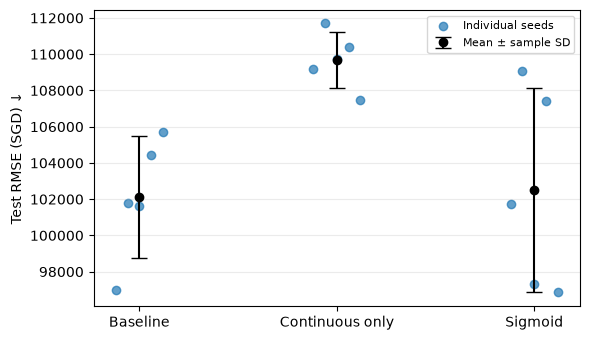

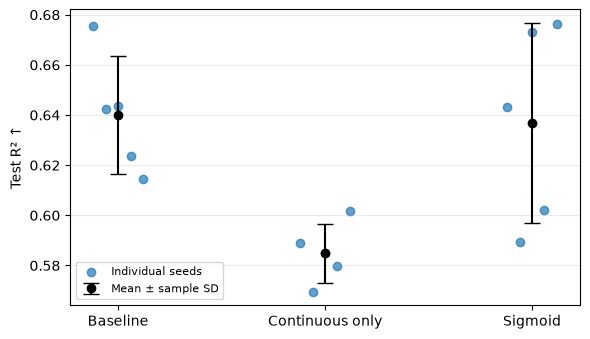

In [7]:
def plot_results(metric, mean_column, sd_column, ylabel, filename):
    fig, ax = plt.subplots(figsize=(6, 3.5))
    positions = np.arange(len(MODELS))
    ax.errorbar(
        positions, summary[mean_column], yerr=summary[sd_column],
        fmt="o", color="black", capsize=6, label="Mean ± sample SD", zorder=3,
    )
    offsets = np.linspace(-0.12, 0.12, len(SEEDS))
    for index, name in enumerate(MODELS):
        values = results[results["model"] == name].set_index("seed").loc[SEEDS, metric]
        ax.scatter(
            index + offsets, values, color="tab:blue", alpha=0.7,
            label="Individual seeds" if index == 0 else None,
        )
    ax.set_xticks(positions, MODELS)
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.25)
    ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(PART_A / filename, dpi=200)
    plt.show()


plot_results("test_rmse", "rmse_mean", "rmse_sd", "Test RMSE (SGD) ↓", "a2_test_rmse.png")
plot_results("test_r2", "r2_mean", "r2_sd", "Test R² ↑", "a2_test_r2.png")
